# Customer_Sales_Exploratory_Data_Analysis_Project

### 1. importing required libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 


### 2. display settings


In [3]:
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

### 3. importing data


In [4]:
df=pd.read_excel("Customer_Sales_Cleaned_Dataset.xlsx")
df.head()

,Customer_ID,Name,Gender,Age,City,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Email,Phone_Number,Country
0,CUST4371,Paul Wilson,Male,52,Kolkata,2025-06-26,2025-05-17 00:00:00,26944,1,peckvictoria@example.com,2131107701,India
1,CUST5957,Jason Thomas,Male,51,Unknown,2021-02-17,2025-07-22 00:00:00,44152,2,owensanthony@example.com,1080761560,India
2,CUST3754,Brittney Martinez,Female,62,Hyderabad,2023-11-05,2024-12-08 00:00:00,31745,2,tara39@example.org,8981006345,India
3,CUST2934,Brenda Pierce,Female,40,Hyderabad,2022-03-13,2025-10-02 00:00:00,39674,1,berrynancy@example.org,8228064204,India
4,CUST5683,Matthew Carroll,Female,41,Chennai,2024-04-05,2024-12-15 00:00:00,0,8,denise84@example.org,2665569480,India


## I. Data Inspection and understanding data

### 4. checking rows and columns in dataset

In [5]:
df.shape

(10127, 12)

### 5. checking columns

In [6]:
df.columns.to_list()

['Customer_ID',
 'Name',
 'Gender',
 'Age',
 'City',
 'Signup_Date',
 'Last_Purchase_Date',
 'Purchase_Amount',
 'Feedback_Score',
 'Email',
 'Phone_Number',
 'Country']

### 6. Checking data types of column 

In [7]:
df.dtypes

Customer_ID                      str
Name                             str
Gender                           str
Age                           object
City                             str
Signup_Date           datetime64[us]
Last_Purchase_Date            object
Purchase_Amount                int64
Feedback_Score                 int64
Email                            str
Phone_Number                   int64
Country                          str
dtype: object

### 7. summary of dataset and information  

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Customer_ID         10127 non-null  str           
 1   Name                10127 non-null  str           
 2   Gender              10127 non-null  str           
 3   Age                 10127 non-null  object        
 4   City                10127 non-null  str           
 5   Signup_Date         10127 non-null  datetime64[us]
 6   Last_Purchase_Date  10127 non-null  object        
 7   Purchase_Amount     10127 non-null  int64         
 8   Feedback_Score      10127 non-null  int64         
 9   Email               10127 non-null  str           
 10  Phone_Number        10127 non-null  int64         
 11  Country             10127 non-null  str           
dtypes: datetime64[us](1), int64(3), object(2), str(6)
memory usage: 1.5+ MB


In [9]:
df.describe().round()

,Signup_Date,Purchase_Amount,Feedback_Score,Phone_Number
count,10127,10127.0,10127.0,1.012700e+04
mean,2023-04-13 13:57:05.812185,26197.0,5.0,4.928784e+09
min,2020-10-08 00:00:00,-500.0,0.0,0.000000e+00
25%,2022-01-18 12:00:00,8178.0,2.0,2.451260e+09
50%,2023-04-06 00:00:00,21786.0,5.0,4.991604e+09
75%,2024-07-15 00:00:00,35722.0,8.0,7.514972e+09
max,2025-10-08 00:00:00,9999999.0,10.0,9.994402e+09
std,NaN,198876.0,3.0,2.985288e+09


### A.findings
1.Age columns data type is object it must numeric we have to convert in numeric 

2.Last_Purchase_Date columns data type is also object it must be date format we have convert to pandas datetime format 

3.Purchase_Amount is Negative its never be negative so we have inspect that column 

## II . Data Cleaning & Formating 

### 1 . Inspecting Age Column

In [10]:
df["Age"].head(10)
df["Age"].unique()


array([52, 51, 62, 40, 41, 'Unknown', 18, 43, 26, 32, 22, 59, 65, 61, 31,
       54, 55, 69, 24, 63, 19, 50, 56, 36, 68, 38, 48, 27, 57, 23, 25, 66,
       28, 30, 44, 46, 20, 37, 67, 35, 58, 29, 'nan years', 39, 49, 47,
       42, 64, 53, 60, 45, 21, 34, 33, 250, 3, -10], dtype=object)

#### A. Findings
1.Unknown ,nan years this kind of string values present in age column 

2.-10 , 250 this kind of invalid numeric value in age column 



In [11]:
# converting string column in numeric column 
df["Age"]=pd.to_numeric(df["Age"],errors="coerce")
print(df["Age"].unique())


[ 52.  51.  62.  40.  41.  nan  18.  43.  26.  32.  22.  59.  65.  61.
  31.  54.  55.  69.  24.  63.  19.  50.  56.  36.  68.  38.  48.  27.
  57.  23.  25.  66.  28.  30.  44.  46.  20.  37.  67.  35.  58.  29.
  39.  49.  47.  42.  64.  53.  60.  45.  21.  34.  33. 250.   3. -10.]


In [12]:
# Checking Datatype Of Age Column 
print(df['Age'].dtypes)

float64


In [13]:
# Making valid age criteria  

df.loc[(df['Age']<0)|(df['Age']>120),'Age']=np.nan
print(df['Age'].unique())



[52. 51. 62. 40. 41. nan 18. 43. 26. 32. 22. 59. 65. 61. 31. 54. 55. 69.
 24. 63. 19. 50. 56. 36. 68. 38. 48. 27. 57. 23. 25. 66. 28. 30. 44. 46.
 20. 37. 67. 35. 58. 29. 39. 49. 47. 42. 64. 53. 60. 45. 21. 34. 33.  3.]


In [14]:
# Checking Null Values in Age Column 
print(df['Age'].isna().sum())

1020


#### B. Findings 
1. Age Column converted in float so age column must be whole number 

2. found missing values, filling missing values with median

In [15]:

# Changining data type of age column float into intger 

df['Age']=df['Age'].astype('Int64')
df['Age'].dtypes

Int64Dtype()

In [16]:
# Filling missing value with average age 
df["Age"]=df["Age"].fillna(df["Age"].median())
print(df["Age"].isna().sum())

0


### 2. Inspecting Last_Purchase_Date column 

In [17]:
df['Last_Purchase_Date'].head()
df['Last_Purchase_Date'].dtypes

dtype('O')

In [18]:
# Last_Purchase_Date columns data types is object converting it into pandas datetime 
df['Last_Purchase_Date']=pd.to_datetime(df['Last_Purchase_Date'],errors='coerce')
df['Last_Purchase_Date'].dtypes

dtype('<M8[us]')

In [19]:
df['Last_Purchase_Date'].head()

0   2025-05-17
1   2025-07-22
2   2024-12-08
3   2025-10-02
4   2024-12-15
Name: Last_Purchase_Date, dtype: datetime64[us]

### 3. Insepecting Purchase Amount Column

In [20]:
# Cheking Null Values in Purchase_Amount Column 
df['Purchase_Amount'].head()
print(df['Purchase_Amount'].isna().sum())

0


In [21]:
# Checking Negative values in Purchase_Amount Column 
print((df['Purchase_Amount'] <0 ).sum())

4


In [22]:
df.loc[df['Purchase_Amount']<0,'Purchase_Amount']

28     -500
68     -500
722    -500
1630   -500
Name: Purchase_Amount, dtype: int64

In [23]:
# Before Changing Original dataframe preseving it 
df_clean=df.copy()

In [24]:
# Converting Negative Values into in postive value of purchase amount column cause purchase amount never be negative 
df_clean['Purchase_Amount']=df_clean['Purchase_Amount'].abs()

In [25]:
# Checking negative values in Purchase_Amount Column 
print((df_clean['Purchase_Amount']<0).sum())

0


### Data Cleaning Note: Purchase Amount

Issue: Four records had negative values in the Purchase_Amount column.

Action Taken: The negative signs were changed to positive using the absolute values, and all records were retained.

Reason: No product returns were recorded, so the negative values were considered possible technical errors.

Impact: The corrected data was used for further EDA.

Note: The corrections should be verified with the data source to ensure accuracy.

In [26]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Customer_ID         10127 non-null  str           
 1   Name                10127 non-null  str           
 2   Gender              10127 non-null  str           
 3   Age                 10127 non-null  Int64         
 4   City                10127 non-null  str           
 5   Signup_Date         10127 non-null  datetime64[us]
 6   Last_Purchase_Date  9118 non-null   datetime64[us]
 7   Purchase_Amount     10127 non-null  int64         
 8   Feedback_Score      10127 non-null  int64         
 9   Email               10127 non-null  str           
 10  Phone_Number        10127 non-null  int64         
 11  Country             10127 non-null  str           
dtypes: Int64(1), datetime64[us](2), int64(3), str(6)
memory usage: 1.5 MB


# III . Exploratory Data Analysis 

### 1.Sales Distribution By Gender 

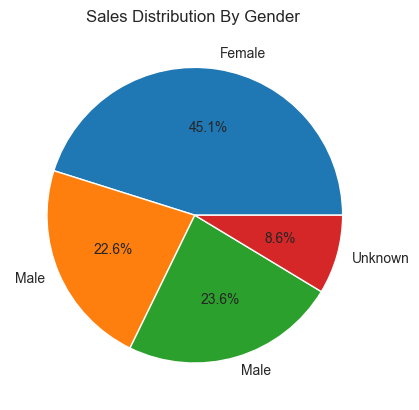

In [27]:
sales_by_gender=df.groupby("Gender")["Purchase_Amount"].sum()

plt.pie(x=sales_by_gender,labels=sales_by_gender.index,autopct="%1.1f%%")
plt.title("Sales Distribution By Gender ")
plt.show()




In [28]:
# Checking why Male value is getting multiple times in chart 
print(df['Gender'].unique())
print(df['Gender'].value_counts())

<ArrowStringArray>
['Male ', 'Female', 'Male', 'Unknown']
Length: 4, dtype: str
Gender
Female     4563
Male       2328
Male       2231
Unknown    1005
Name: count, dtype: int64


In [29]:
# Here Male value showing double becaue extra space in Male string so relsoving this issue 
df["Gender"]=df["Gender"].str.strip().str.lower()
df["Gender"]=df["Gender"].str.title()

In [30]:
df["Gender"].unique()

<ArrowStringArray>
['Male', 'Female', 'Unknown']
Length: 3, dtype: str

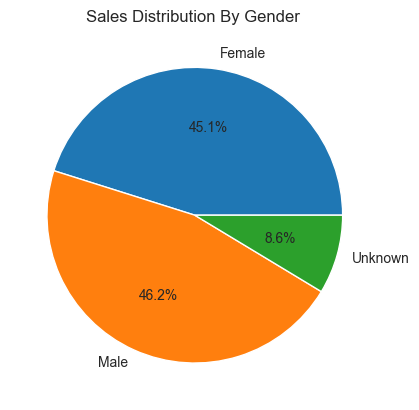

In [31]:
# Sales Distribution By Gender 
sales_by_gender=df.groupby("Gender")["Purchase_Amount"].sum()
plt.pie(x=sales_by_gender,labels=sales_by_gender.index,autopct="%1.1f%%")
plt.title("Sales Distribution By Gender ")
plt.show()

### 2.Sales Distribution By AgeGroup

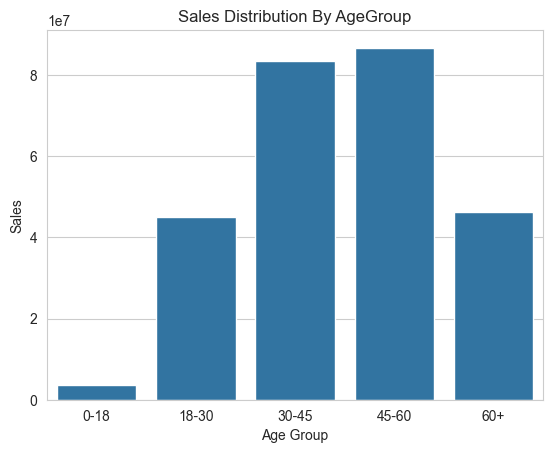

In [32]:
bins=[0,18,30,45,60,120]
label=["0-18","18-30","30-45","45-60","60+"]

df["Age_Group"]=pd.cut(df["Age"], bins=bins,labels=label, include_lowest=True)

sales_by_agegroup=df.groupby("Age_Group",observed=False) ["Purchase_Amount"].sum().reset_index()

sns.barplot(data=sales_by_agegroup,x='Age_Group',y="Purchase_Amount")
plt.title("Sales Distribution By AgeGroup")
plt.xlabel("Age Group")
plt.ylabel("Sales")
plt.show()

In [33]:
df_clean.head()

,Customer_ID,Name,Gender,Age,City,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Email,Phone_Number,Country
0,CUST4371,Paul Wilson,Male,52,Kolkata,2025-06-26,2025-05-17,26944,1,peckvictoria@example.com,2131107701,India
1,CUST5957,Jason Thomas,Male,51,Unknown,2021-02-17,2025-07-22,44152,2,owensanthony@example.com,1080761560,India
2,CUST3754,Brittney Martinez,Female,62,Hyderabad,2023-11-05,2024-12-08,31745,2,tara39@example.org,8981006345,India
3,CUST2934,Brenda Pierce,Female,40,Hyderabad,2022-03-13,2025-10-02,39674,1,berrynancy@example.org,8228064204,India
4,CUST5683,Matthew Carroll,Female,41,Chennai,2024-04-05,2024-12-15,0,8,denise84@example.org,2665569480,India


### 3. Monthly Sales Trends 

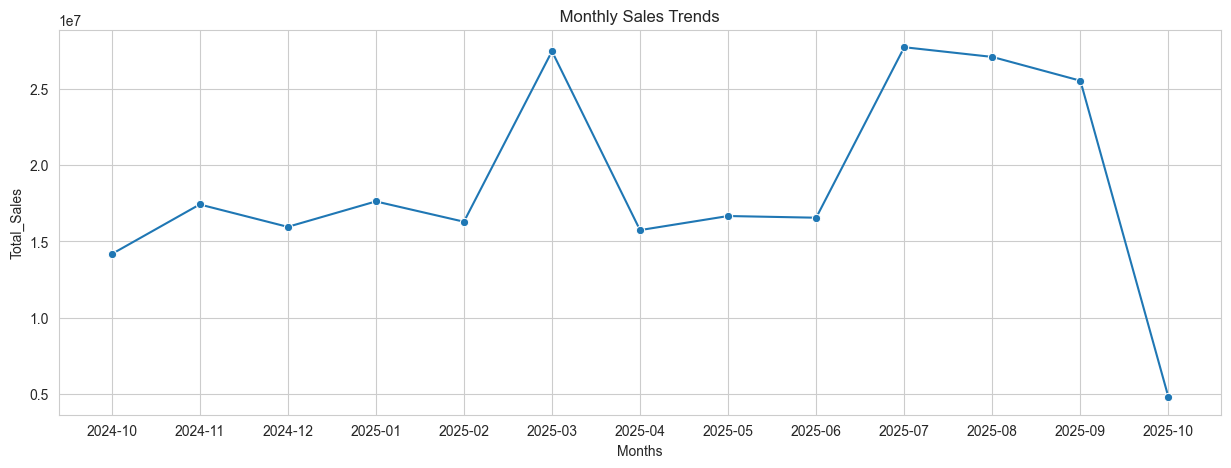

In [34]:
plt.figure(figsize=(15,5))
# Extracting Months From Last_Purchase_Date
df["Months"]=(df["Last_Purchase_Date"].dt.to_period("M"))
# Convert months to strings for plotting
df["Months"] = (df["Months"].astype(str))


Monthly_Sales_Trend=df.groupby("Months",as_index=False)["Purchase_Amount"].sum()

sns.lineplot(data=Monthly_Sales_Trend,x="Months",y="Purchase_Amount",marker="o")
plt.title(" Monthly Sales Trends ")
plt.xlabel("Months")
plt.ylabel("Total_Sales")
plt.show()


### 4. Customer Data Correlation Heatmap

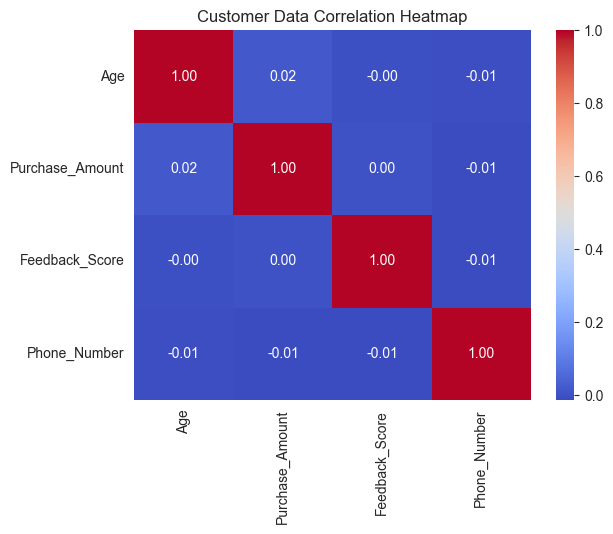

In [35]:
df1=df.select_dtypes(include='number').corr()
sns.heatmap(data=df1,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Customer Data Correlation Heatmap")
plt.show()

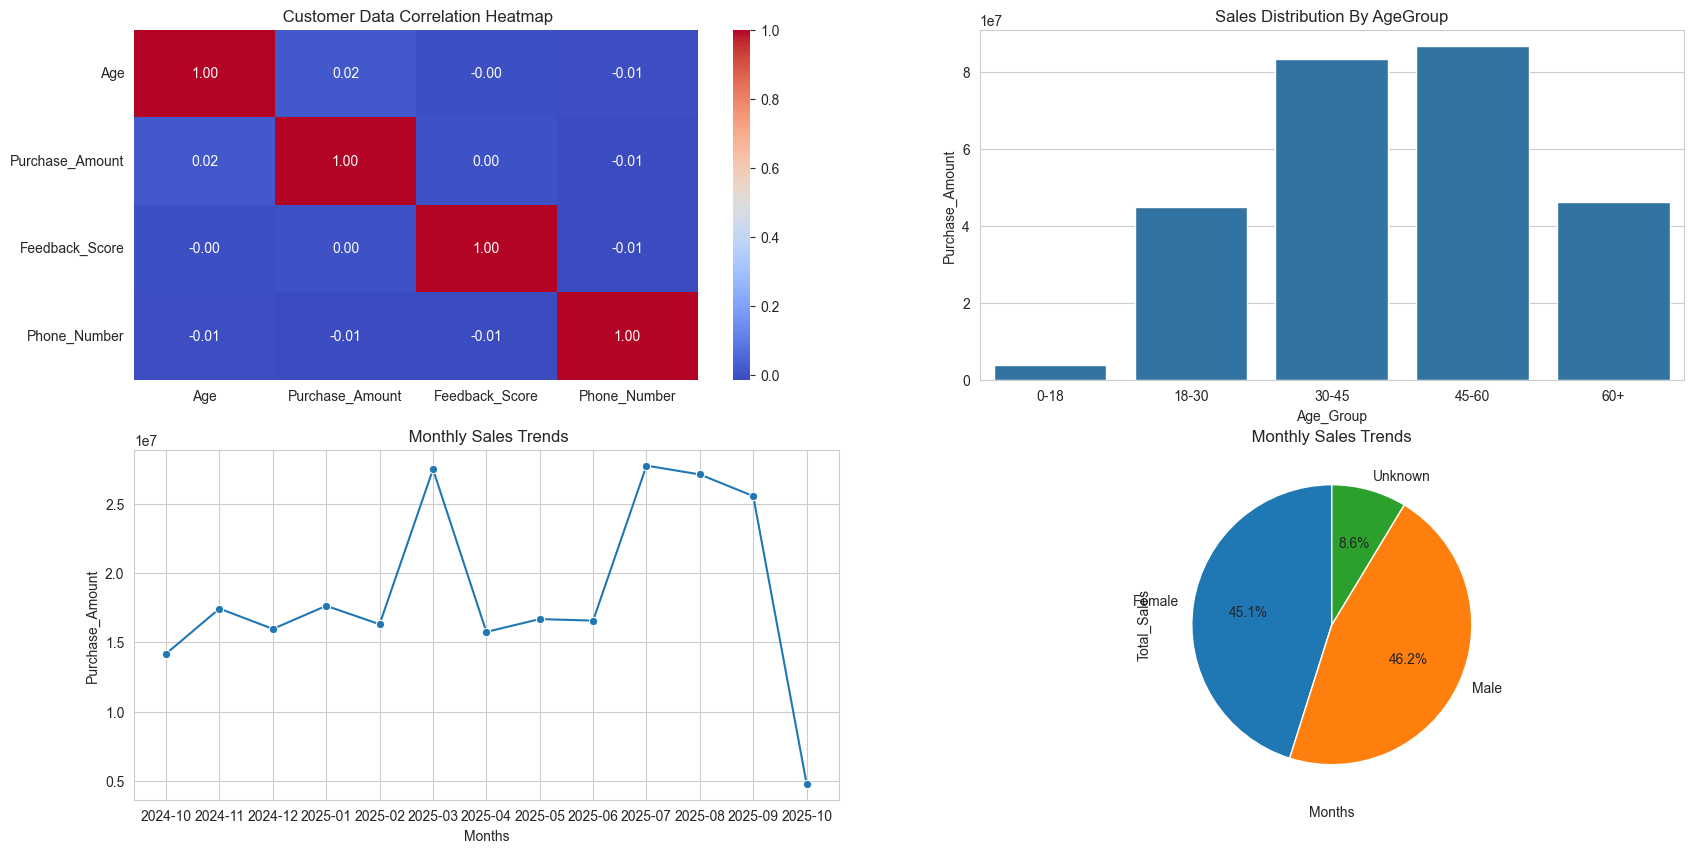

In [37]:

# Gathered all chart in one place 

fig , ax=plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(20,10)
    
)
# #Sales Distribution By Gender - Pie Chart 
# sales_by_gender=df.groupby("Gender")["Purchase_Amount"].sum()
# plt.pie(x=sales_by_gender,labels=sales_by_gender.index,autopct="%1.1f%%").ax=ax[0.0]
# ax[0,0].set_title("Sales Distribution By Gender")

ax[1, 1].pie(
    sales_by_gender,
    labels=sales_by_gender.index,
    autopct="%1.1f%%",
    startangle=90
)

ax[1, 1].set_title("Sales Distribution by Gender")


#Sales Distribution By AgeGroup
sns.barplot(data=sales_by_agegroup,x='Age_Group',y="Purchase_Amount",ax=ax[0,1])
ax[0,1].set_title("Sales Distribution By AgeGroup")
plt.xlabel("Age Group")
plt.ylabel("Sales")

#Monthly Sales Trends 
sns.lineplot(data=Monthly_Sales_Trend,x="Months",y="Purchase_Amount",marker="o",ax=ax[1,0])
plt.title(" Monthly Sales Trends ")
ax[1,0].set_title(" Monthly Sales Trends")
plt.xlabel("Months")
plt.ylabel("Total_Sales")

#Customer Data Correlation Heatmap
df1=df.select_dtypes(include='number').corr()
sns.heatmap(data=df1,annot=True,cmap="coolwarm",fmt=".2f",ax=ax[0,0])
ax[0,0].set_title(" Customer Data Correlation Heatmap")

plt.show()


## IV. KPI 

In [39]:
df.head()

,Customer_ID,Name,Gender,Age,City,Signup_Date,Last_Purchase_Date,Purchase_Amount,Feedback_Score,Email,Phone_Number,Country,Age_Group,Months
0,CUST4371,Paul Wilson,Male,52,Kolkata,2025-06-26,2025-05-17,26944,1,peckvictoria@example.com,2131107701,India,45-60,2025-05
1,CUST5957,Jason Thomas,Male,51,Unknown,2021-02-17,2025-07-22,44152,2,owensanthony@example.com,1080761560,India,45-60,2025-07
2,CUST3754,Brittney Martinez,Female,62,Hyderabad,2023-11-05,2024-12-08,31745,2,tara39@example.org,8981006345,India,60+,2024-12
3,CUST2934,Brenda Pierce,Female,40,Hyderabad,2022-03-13,2025-10-02,39674,1,berrynancy@example.org,8228064204,India,30-45,2025-10
4,CUST5683,Matthew Carroll,Female,41,Chennai,2024-04-05,2024-12-15,0,8,denise84@example.org,2665569480,India,30-45,2024-12


In [59]:
# 1.Total Customer 
print("Total Customer =",df["Customer_ID"].nunique())


#2. Total_Amount 
print("Total_Amount =",df["Purchase_Amount"].sum())

#3.Total_Avg_Amount 
print("Average_Amount =",df["Purchase_Amount"].mean().round(2))

## Average_feedback_Score

print("Average_feedback_Score =",df["Feedback_Score"].mean().round())

Total Customer = 9001
Total_Amount = 265295613
Average_Amount = 26196.86
Average_feedback_Score = 5.0
